# 2 · Modelos, desbalance y calibración

1. Línea base (regla de negocio) vs. regresión logística vs. LightGBM.
2. **Desbalance**: ¿sirve dar más peso a la clase minoritaria o remuestrear (submuestreo, SMOTE)?
3. **Calibración**: ¿la probabilidad que da el modelo es real?

Todo lo de este notebook se calcula **fuera de pliegue** (5 pliegues estratificados sobre el entrenamiento). Los resultados completos los genera `python -m campana.entrenar`; aquí se leen y se reproduce lo esencial.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src")); sys.path.insert(0, str(RAIZ))
from campana import config, datos, modelos, explicar, evaluacion as ev
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

In [2]:
comp = pd.read_csv(RAIZ / "reports" / "comparacion_desbalance.csv")
comp[["modelo", "estrategia", "auc", "average_precision", "brier", "brier_calibrado", "prob_media",
      "ganancia_umbral_teorico", "ganancia_calibrado"]]

,modelo,estrategia,auc,average_precision,brier,brier_calibrado,prob_media,ganancia_umbral_teorico,ganancia_calibrado
0,regla,ninguna,0.6740,0.2738,0.0884,NaN,0.1127,NaN,NaN
1,logistica,ninguna,0.7887,0.4479,0.0788,0.0787,0.1127,"131,968.0000","131,296.0000"
2,logistica,pesos,0.7893,0.4435,0.1649,0.0789,0.3913,"33,368.0000","132,232.0000"
3,logistica,submuestreo,0.7874,0.4387,0.1670,0.0793,0.3935,"33,376.0000","131,080.0000"
4,logistica,smote,0.7504,0.3956,0.1591,0.0828,0.3472,"53,168.0000","112,512.0000"
5,lightgbm,ninguna,0.7989,0.4644,0.0769,0.0771,0.1126,"136,280.0000","136,008.0000"
6,lightgbm,pesos,0.7994,0.4640,0.1552,0.0771,0.3772,"33,360.0000","135,872.0000"
7,lightgbm,submuestreo,0.7937,0.4511,0.1631,0.0781,0.3881,"33,360.0000","135,016.0000"
8,lightgbm,smote,0.7694,0.4164,0.1338,0.0811,0.3106,"51,392.0000","119,400.0000"


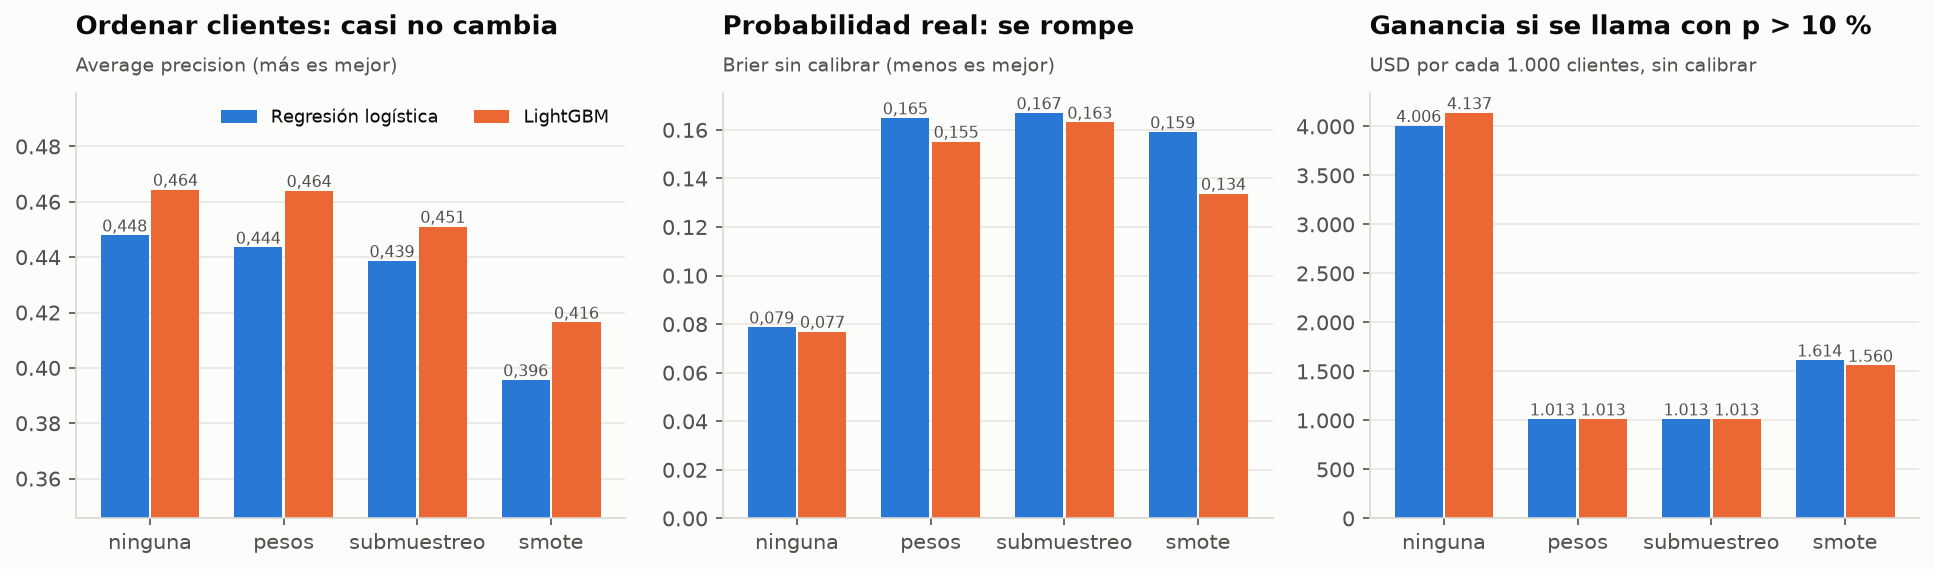

In [3]:
display(Image(RAIZ / "reports" / "figures" / "02_comparacion_desbalance.png"))

### Lectura

- **Ordenar** (AUC / average precision): pesos y submuestreo **no mejoran** el orden; SMOTE lo **empeora** (inventa clientes interpolando, y con tantas categóricas los sintéticos son poco realistas).
- **Probabilidad**: con pesos o remuestreo el modelo cree que la tasa es ~38 % cuando es 11 %. El Brier se **duplica**.
- **Dinero**: si se usa la regla «llamar si p > 10 %» con esas probabilidades infladas, se termina llamando a casi todos → la ganancia cae de ~4.100 a ~1.000 USD por cada 1.000 clientes (lo mismo que llamar a todos).
- Después de **calibrar** todas las estrategias quedan parecidas: el desbalance no se arregla remuestreando, se arregla **eligiendo bien el umbral** con probabilidades calibradas.

**Elección:** LightGBM sin ajuste de desbalance (mejor ganancia calibrada fuera de pliegue).

## 2.1 Reproducir un punto clave: pesos de clase vs. sin ajuste

In [4]:
df = datos.cargar()
ent, pru = datos.particion_estratificada(df)
X, y = datos.X_y(ent)
Xp, yp = datos.X_y(pru)
oof_sin = ev.fuera_de_pliegue("lightgbm", "ninguna", X, y)
oof_pesos = ev.fuera_de_pliegue("lightgbm", "pesos", X, y)
pd.DataFrame({"sin ajuste": ev.metricas(y, oof_sin), "pesos balanceados": ev.metricas(y, oof_pesos)})

,sin ajuste,pesos balanceados
auc,0.7989,0.7994
average_precision,0.4644,0.4640
brier,0.0769,0.1552
log_loss,0.2724,0.4982
prob_media,0.1126,0.3772
tasa_real,0.1127,0.1127


## 2.2 Calibración

Se comparan tres opciones con predicciones fuera de pliegue (el calibrador de cada fila tampoco la vio): sin calibrar, Platt (logística sobre el logit) e isotónica.

In [5]:
pd.Series({"sin calibrar": ev.brier_score_loss(y, oof_sin),
           "platt": ev.brier_score_loss(y, ev.calibrar_fuera_de_pliegue(oof_sin, y, "platt")),
           "isotonica": ev.brier_score_loss(y, ev.calibrar_fuera_de_pliegue(oof_sin, y, "isotonica")),
           "pesos → isotónica": ev.brier_score_loss(y, ev.calibrar_fuera_de_pliegue(oof_pesos, y, "isotonica"))},
          name="Brier fuera de pliegue").to_frame()

,Brier fuera de pliegue
sin calibrar,0.0769
platt,0.0770
isotonica,0.0771
pesos → isotónica,0.0771


LightGBM con pérdida logarítmica y **sin pesos** ya sale casi calibrado (Platt prácticamente no cambia nada); se deja Platt en el pipeline porque es barato y protege si cambian los hiperparámetros. Con pesos, la isotónica recupera casi todo.

Ahora en **prueba** (se mira una sola vez, con el modelo final guardado):

In [6]:
import joblib
paquete = joblib.load(RAIZ / "models" / "modelo_campana.joblib")
modelo, calibrador = paquete["modelo"], paquete["calibrador"]
p_final = calibrador.transform(modelos.probabilidad(modelo, Xp))
m_pesos = modelos.entrenar("lightgbm", "pesos", X, y)
p_pesos = modelos.probabilidad(m_pesos, Xp)
for nombre, p in [("final (calibrado)", p_final), ("con pesos, sin calibrar", p_pesos)]:
    print(f"{nombre:25s} Brier {ev.brier_score_loss(yp, p):.4f} · prob. media {p.mean():.1%} · tasa real {yp.mean():.1%}")
ev.tabla_calibracion(yp, p_final)

final (calibrado)         Brier 0.0751 · prob. media 11.2% · tasa real 11.3%
con pesos, sin calibrar   Brier 0.1520 · prob. media 37.8% · tasa real 11.3%


,prob_predicha,tasa_real
0,0.0273,0.0303
1,0.0332,0.0388
2,0.0406,0.0279
3,0.0469,0.0376
4,0.0525,0.0450
5,0.0595,0.0498
6,0.0677,0.0608
7,0.0837,0.0922
8,0.1959,0.2102
9,0.5127,0.5340


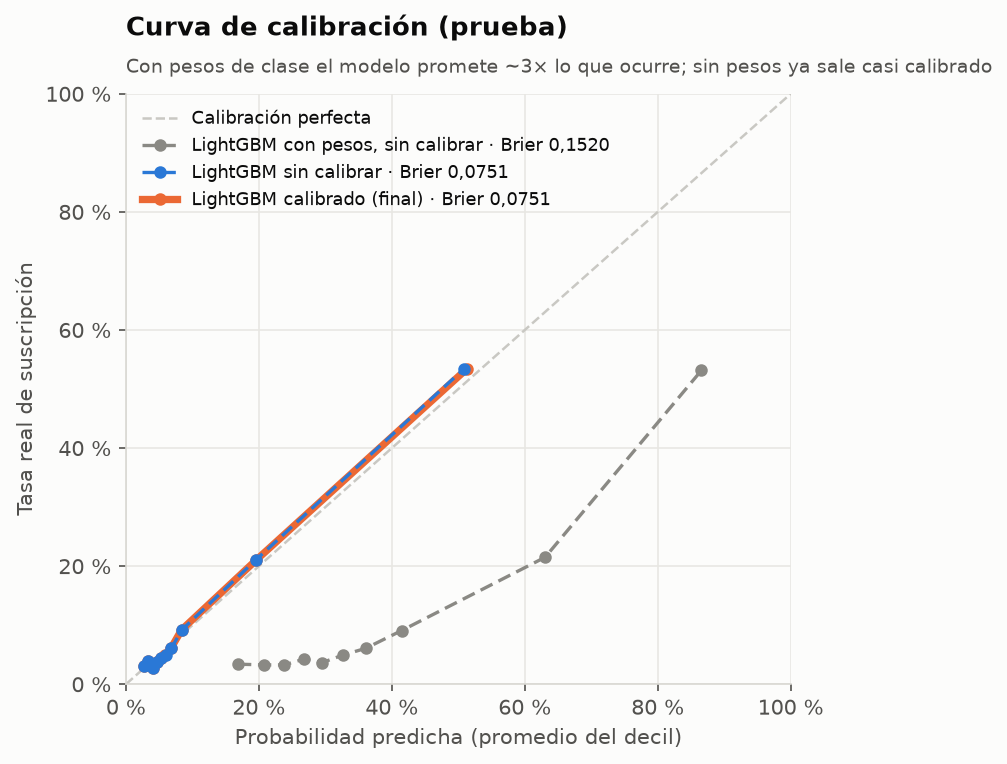

In [7]:
display(Image(RAIZ / "reports" / "figures" / "03_calibracion.png"))

## 2.3 Métricas en prueba (8.236 clientes)

In [8]:
pd.read_csv(RAIZ / "reports" / "metricas_prueba.csv", index_col=0)[
    ["auc", "average_precision", "brier", "brier_skill", "log_loss", "prob_media", "tasa_real"]]

,auc,average_precision,brier,brier_skill,log_loss,prob_media,tasa_real
modelo,,,,,,,
Regla por segmento,0.6752,0.2458,0.0898,0.1015,0.3178,0.1126,0.1127
"Regresión logística (pesos, calibrada)",0.8008,0.4436,0.0785,0.2150,0.2752,0.1116,0.1127
"LightGBM (ninguna, sin calibrar)",0.8146,0.4896,0.0751,0.2490,0.2650,0.1119,0.1127
"LightGBM (ninguna, calibrado) · FINAL",0.8146,0.4896,0.0751,0.2492,0.2649,0.1120,0.1127
"LightGBM (pesos, sin calibrar)",0.8138,0.4831,0.1520,-0.5202,0.4914,0.3777,0.1127


- LightGBM supera a la logística por poco en AUC (0,815 vs 0,801) y algo más en *average precision* (0,49 vs 0,44): hay interacciones (economía × historia del cliente) que el modelo lineal no capta.
- La regla de negocio (tasa por segmento de campaña anterior × tipo de teléfono) se queda muy atrás: AUC 0,675.
- **Brier skill** 0,25: el modelo reduce un 25 % el error cuadrático respecto de predecir siempre la tasa base. Con pesos sin calibrar es **negativo** (peor que no tener modelo).